In [2]:
import sys
from pathlib import Path

project_root = Path("/mnt/x/segmentation_cfos")
sys.path.insert(0, str(project_root))

import torch
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
from src.data.io_utils import read_tif_image, convert_image_to_array
from src.models.swin_unetr_monai import SwinUNETR3D
from src.inference.predict import load_model

/home/mima/anaconda3/envs/segmentation_cfos/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-07-28 15:43:37.510881: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [ ]:
model_path = project_root / "outputs" / "swin_3class_slices40_focal" / "checkpoints" / "best_model.pth"
data_dir = Path("/mnt/x/donnees/pachs_64_3classes_filtered_slices")
splits_dir = data_dir / "splits"
output_pred_dir = project_root / "outputs" / "swin_3class_slices40_focal" / "predictions"
output_pred_dir.mkdir(parents=True, exist_ok=True)

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Modèle: {model_path}")
print(f"Device: {device}")
print(f"Dossier prédictions: {output_pred_dir}")

Modèle: /mnt/x/segmentation_cfos/outputs/swin_3class_slices40_focal/checkpoints/best_model.pth
Device: cuda
Dossier prédictions: /mnt/x/segmentation_cfos/outputs/swin_3class_slices40_focal/predictions


In [ ]:
print("Chargement du modèle...")
checkpoint = torch.load(model_path, map_location=device)
model = SwinUNETR3D(
    in_channels=1,
    out_channels=3,  
    feature_size=48,
    drop_rate=0.0,
    attn_drop_rate=0.0,
    use_checkpoint=False
)
# Charger les poids
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

In [5]:
print("Chargement des patches de test...")
test_file = splits_dir / "test.txt"
with open(test_file, 'r') as f:
    test_names = [line.strip() for line in f.readlines() if line.strip()]

print(f"Nombre de patches de test: {len(test_names)}")


Chargement des patches de test...
Nombre de patches de test: 619


In [6]:
NUM_SAMPLES = 10
selected_indices = random.sample(range(len(test_names)), min(NUM_SAMPLES, len(test_names)))
selected_names = [test_names[i] for i in selected_indices]
print(f"Patches sélectionnés: {len(selected_names)}")

Patches sélectionnés: 10


In [7]:
def predict_patch(model, image_path, device):
    """Prédit un patch et retourne la prédiction"""
    image_sitk = read_tif_image(str(image_path))
    image = convert_image_to_array(image_sitk)
    
    # Normaliser l'image
    min_val = image.min()
    max_val = image.max()
    if max_val - min_val > 0:
        image = (image.astype(np.float32) - min_val) / (max_val - min_val)
    else:
        image = np.zeros_like(image, dtype=np.float32)
    
    # Ajouter dimensions
    image_tensor = torch.from_numpy(image).float().unsqueeze(0).unsqueeze(0).to(device)
    
    with torch.no_grad():
        pred = model(image_tensor)
        pred = torch.softmax(pred, dim=1)
        pred_class = torch.argmax(pred, dim=1).cpu().numpy().squeeze()
    
    return pred_class

In [11]:
print("Prédiction des patches sélectionnés...")
print("-" * 40)

predictions = []
image_dir = data_dir / "images"
mask_dir = data_dir / "masks"

for name in tqdm(selected_names, desc="Prédiction"):
    image_path = image_dir / f"{name}.tif"
    mask_path = mask_dir / f"{name}.tif"  
    
    # Prédire
    pred = predict_patch(model, image_path, device)
    
    # Charger le mask réel (en .tif)
    mask_sitk = read_tif_image(str(mask_path))
    mask_real = convert_image_to_array(mask_sitk)
    
    # Charger l'image
    image_sitk = read_tif_image(str(image_path))
    image = convert_image_to_array(image_sitk)
    
    pred_path_npy = output_pred_dir / f"{name}_pred.npy"
    np.save(pred_path_npy, pred)
    
    from src.data.io_utils import save_image, convert_array_to_image
    pred_image = convert_array_to_image(pred.astype(np.uint8))
    pred_path_tif = output_pred_dir / f"{name}_pred.tif"
    save_image(pred_image, str(pred_path_tif))
    
    predictions.append({
        "name": name,
        "image": image,
        "mask_real": mask_real,
        "pred": pred
    })

print(f"✅ Prédictions sauvegardées dans: {output_pred_dir}")
print(f"   - Format .npy: {len(predictions)} fichiers")
print(f"   - Format .tif: {len(predictions)} fichiers")

Prédiction des patches sélectionnés...
----------------------------------------


Prédiction: 100%|██████████████████████████████████████████████████████████| 10/10 [00:36<00:00,  3.63s/it]

✅ Prédictions sauvegardées dans: /mnt/x/segmentation_cfos/outputs/swin_3class_slices40_focal/predictions
   - Format .npy: 10 fichiers
   - Format .tif: 10 fichiers


In [13]:

def visualize_prediction_3class(image, mask_real, pred, name, slice_idx=None):
    """Visualise l'image, le mask réel, la prédiction et les superpositions"""
    
    if slice_idx is None:
        slice_idx = image.shape[0] // 2
    
    img_slice = image[slice_idx, :, :]
    if img_slice.max() > 1:
        img_slice = img_slice / img_slice.max()
    
    mask_real_slice = mask_real[slice_idx, :, :]
    pred_slice = pred[slice_idx, :, :]
    # Mask réel en RGB
    rgb_real = np.zeros((mask_real_slice.shape[0], mask_real_slice.shape[1], 3), dtype=np.float32)
    rgb_real[mask_real_slice == 0] = [0, 0, 0]
    rgb_real[mask_real_slice == 1] = [1, 0, 0]
    rgb_real[mask_real_slice == 2] = [0, 1, 0]
    
    # Prédiction en RGB
    rgb_pred = np.zeros((pred_slice.shape[0], pred_slice.shape[1], 3), dtype=np.float32)
    rgb_pred[pred_slice == 0] = [0, 0, 0]
    rgb_pred[pred_slice == 1] = [1, 0, 0]
    rgb_pred[pred_slice == 2] = [0, 1, 0]
    
    # Superposition: Image + Mask Réel
    overlay_real = np.stack([img_slice, img_slice, img_slice], axis=-1)
    overlay_real[mask_real_slice == 1, 0] = 1
    overlay_real[mask_real_slice == 1, 1] = 0
    overlay_real[mask_real_slice == 1, 2] = 0
    overlay_real[mask_real_slice == 2, 0] = 0
    overlay_real[mask_real_slice == 2, 1] = 1
    overlay_real[mask_real_slice == 2, 2] = 0
    
    # Superposition: Image + Prédiction
    overlay_pred = np.stack([img_slice, img_slice, img_slice], axis=-1)
    overlay_pred[pred_slice == 1, 0] = 1
    overlay_pred[pred_slice == 1, 1] = 0
    overlay_pred[pred_slice == 1, 2] = 0
    overlay_pred[pred_slice == 2, 0] = 0
    overlay_pred[pred_slice == 2, 1] = 1
    overlay_pred[pred_slice == 2, 2] = 0
    
    # Créer la figure
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Ligne 1: Image, Mask Réel, Prédiction
    axes[0, 0].imshow(img_slice, cmap='gray')
    axes[0, 0].set_title(f'Image - Slice {slice_idx}')
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(rgb_real)
    axes[0, 1].set_title(f'Mask Réel\nNeurones: {(mask_real_slice==1).sum()}, Vaisseaux: {(mask_real_slice==2).sum()}')
    axes[0, 1].axis('off')
    
    axes[0, 2].imshow(rgb_pred)
    axes[0, 2].set_title(f'Prédiction\nNeurones: {(pred_slice==1).sum()}, Vaisseaux: {(pred_slice==2).sum()}')
    axes[0, 2].axis('off')
    
    # Ligne 2: Overlays
    axes[1, 0].imshow(overlay_real)
    axes[1, 0].set_title('Image + Mask Réel (Rouge=Neurones, Vert=Vaisseaux)')
    axes[1, 0].axis('off')
    
    axes[1, 1].imshow(overlay_pred)
    axes[1, 1].set_title('Image + Prédiction (Rouge=Neurones, Vert=Vaisseaux)')
    axes[1, 1].axis('off')
    
    # Comparaison: Mask Réel vs Prédiction (superposés)
    overlay_compare = np.zeros((mask_real_slice.shape[0], mask_real_slice.shape[1], 3), dtype=np.float32)
    # Vert = Prédiction correcte (Neurones)
    correct_neurons = (mask_real_slice == 1) & (pred_slice == 1)
    overlay_compare[correct_neurons] = [0, 1, 0]
    # Rouge = Neurones manqués (Faux négatifs)
    fn_neurons = (mask_real_slice == 1) & (pred_slice != 1)
    overlay_compare[fn_neurons] = [1, 0, 0]
    # Jaune = Vaisseaux manqués
    fn_vessels = (mask_real_slice == 2) & (pred_slice != 2)
    overlay_compare[fn_vessels] = [1, 1, 0]
    # Bleu = Faux positifs
    fp = (mask_real_slice == 0) & (pred_slice != 0)
    overlay_compare[fp] = [0, 0, 1]
    
    axes[1, 2].imshow(overlay_compare)
    axes[1, 2].set_title('Comparaison (Vert=Correct, Rouge=Manqué, Jaune=Vaisseau, Bleu=FP)')
    axes[1, 2].axis('off')
    
    # Légende
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='black', label='Fond (0)'),
        Patch(facecolor='red', label='Neurones (1)'),
        Patch(facecolor='green', label='Vaisseaux (2)')
    ]
    axes[0, 2].legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.15, 1))
    
    plt.suptitle(f'Patch: {name}', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # Statistiques
    print(f"\nStatistiques du patch {name}:")
    print(f"  Neurones réels: {(mask_real == 1).sum():,}")
    print(f"  Vaisseaux réels: {(mask_real == 2).sum():,}")
    print(f"  Neurones prédits: {(pred == 1).sum():,}")
    print(f"  Vaisseaux prédits: {(pred == 2).sum():,}")



VISUALISATION DES PRÉDICTIONS

--- Patch 1/10: sample_001000004 ---


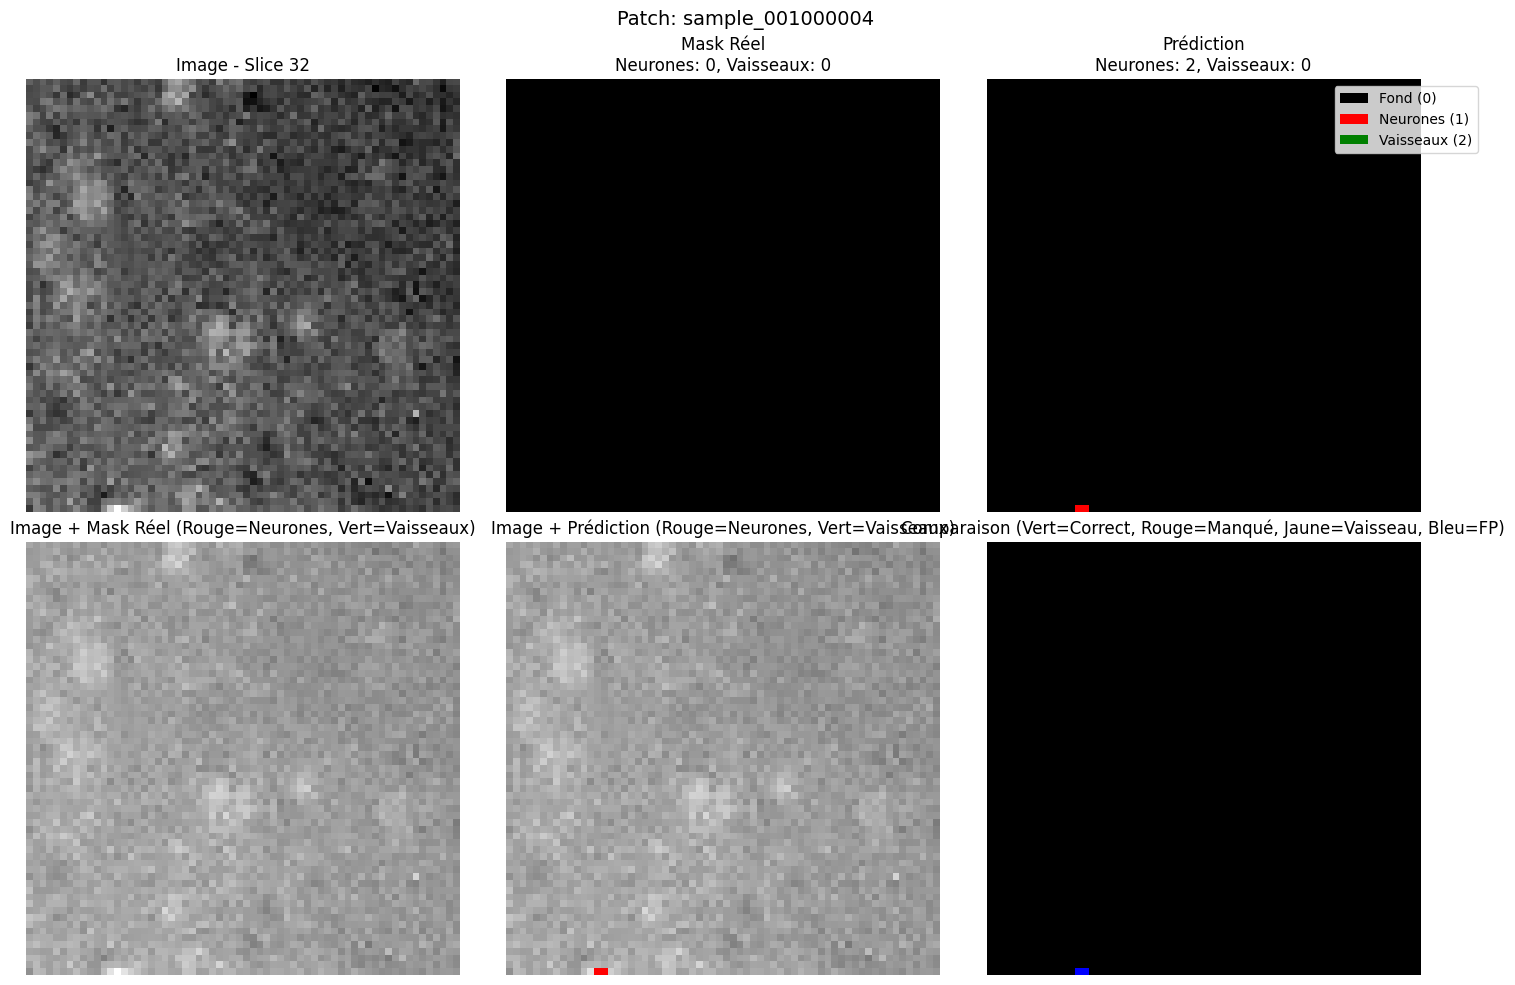


Statistiques du patch sample_001000004:
  Neurones réels: 473
  Vaisseaux réels: 0
  Neurones prédits: 744
  Vaisseaux prédits: 0

--- Patch 2/10: sample_070000029 ---


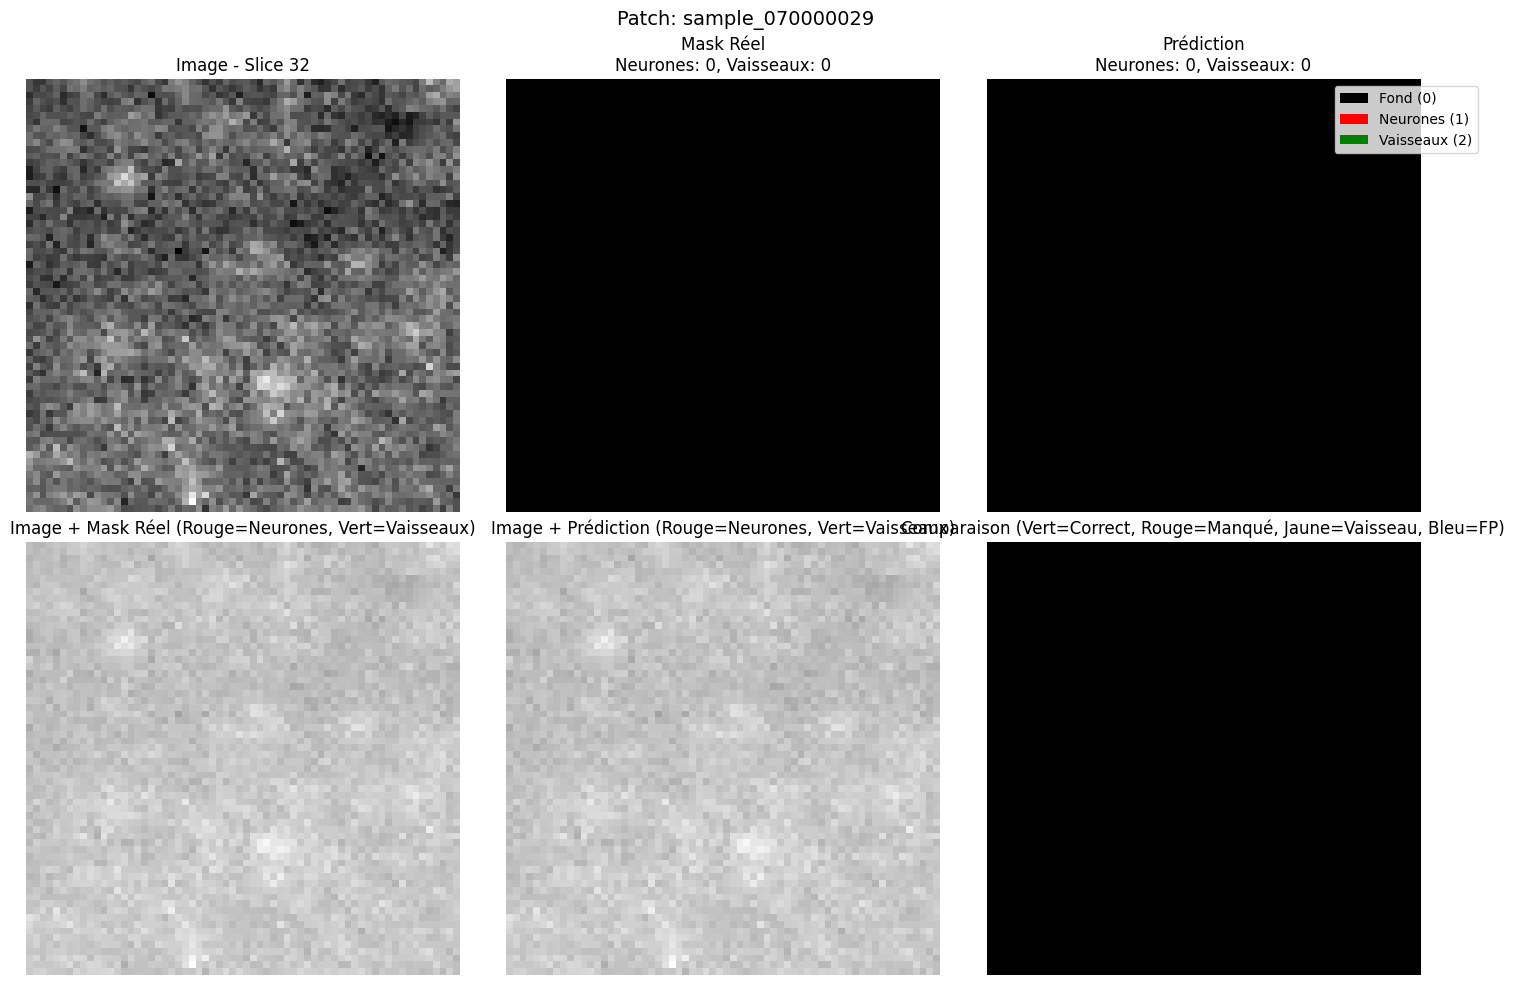


Statistiques du patch sample_070000029:
  Neurones réels: 691
  Vaisseaux réels: 0
  Neurones prédits: 877
  Vaisseaux prédits: 0

--- Patch 3/10: sample_077001754 ---


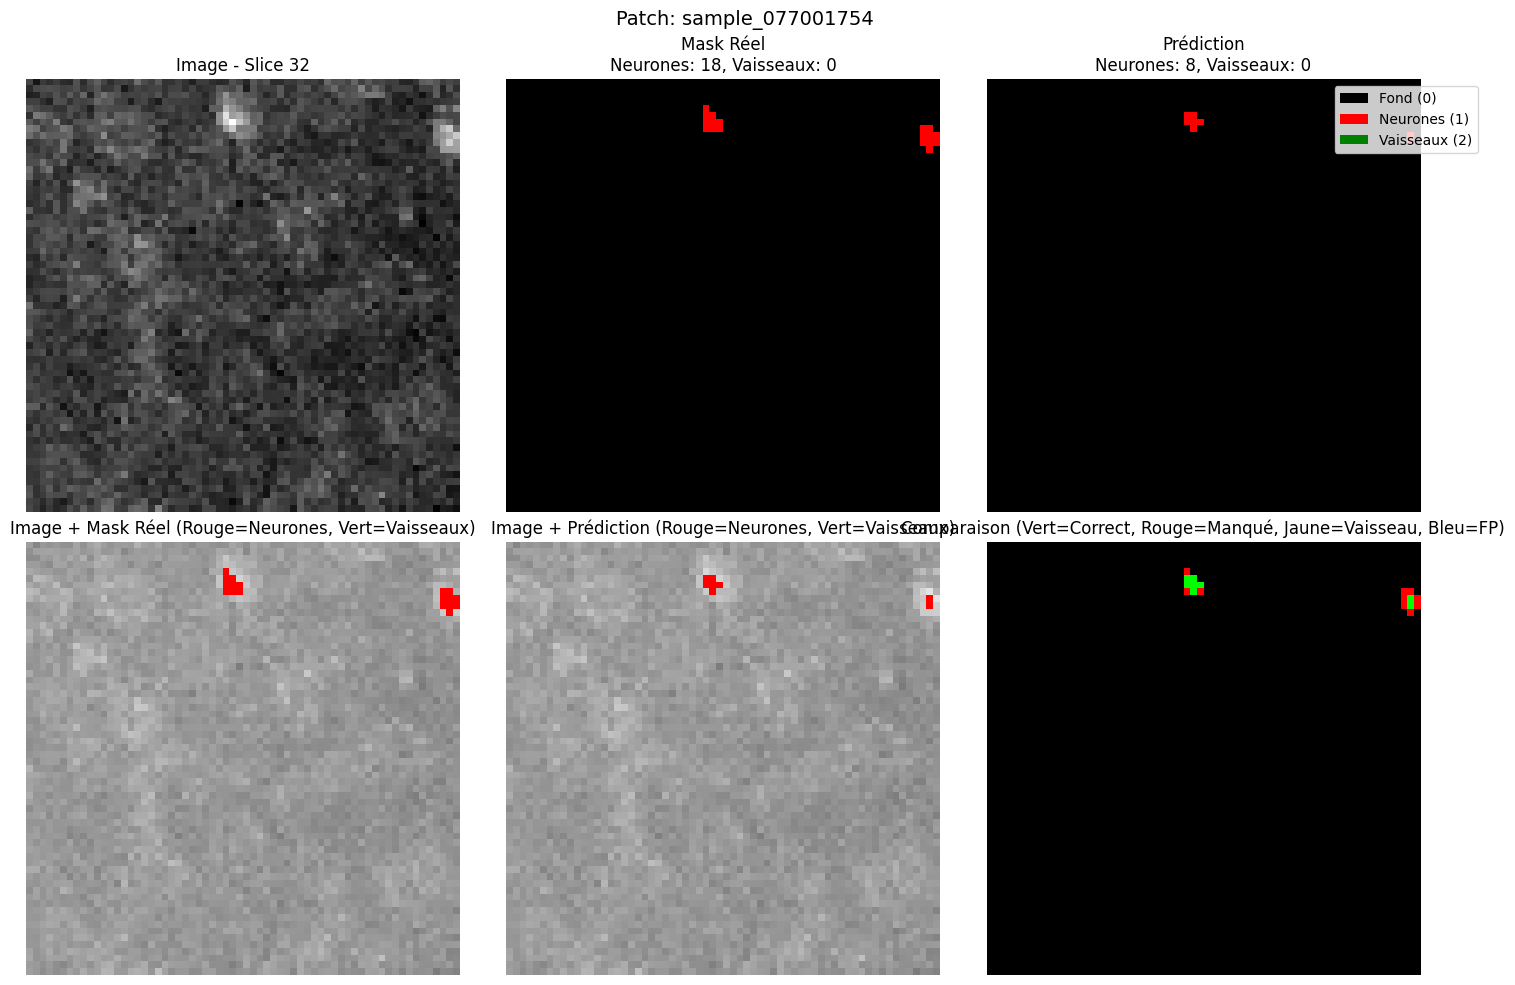


Statistiques du patch sample_077001754:
  Neurones réels: 1,347
  Vaisseaux réels: 0
  Neurones prédits: 1,160
  Vaisseaux prédits: 6

--- Patch 4/10: sample_066000041 ---


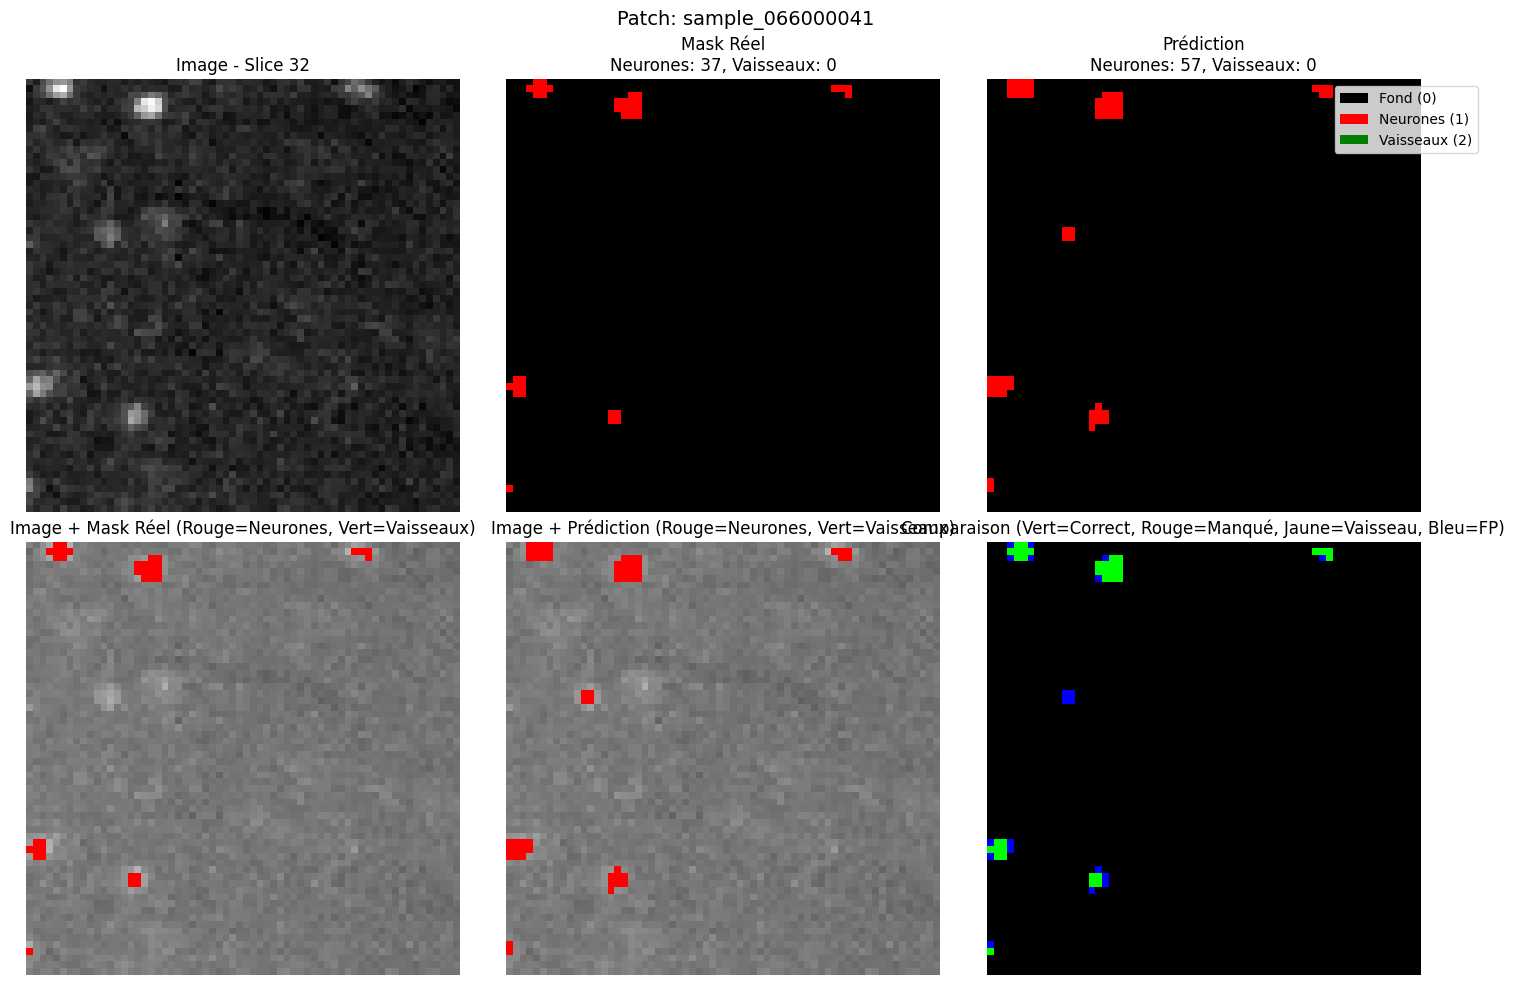


Statistiques du patch sample_066000041:
  Neurones réels: 670
  Vaisseaux réels: 0
  Neurones prédits: 990
  Vaisseaux prédits: 0

--- Patch 5/10: sample_050000032 ---


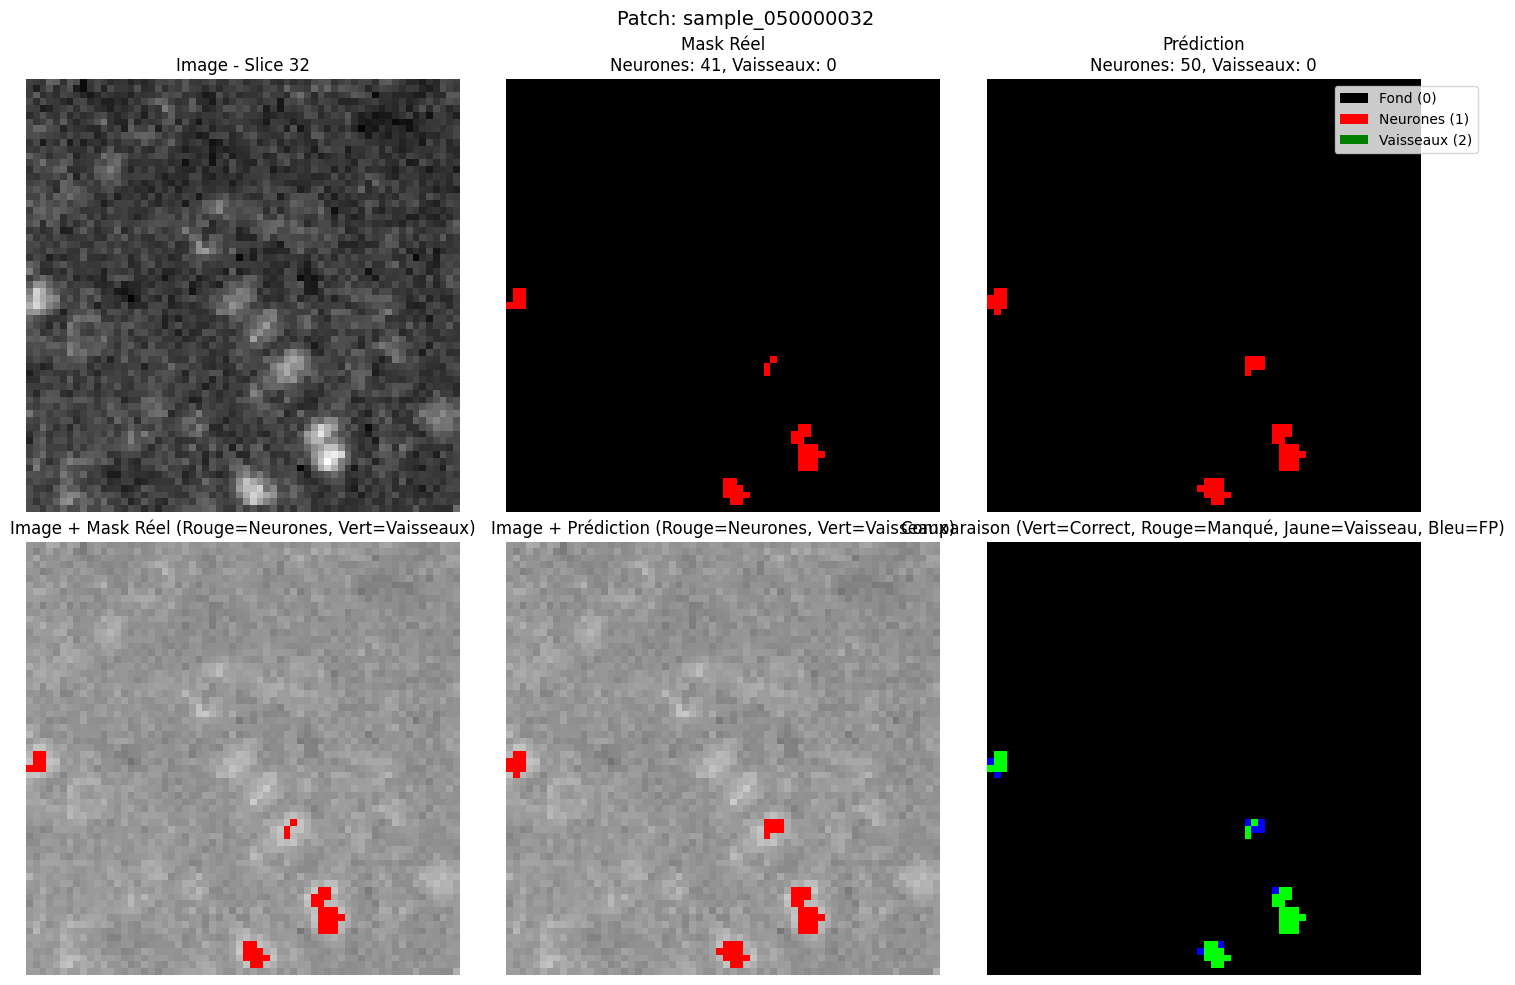


Statistiques du patch sample_050000032:
  Neurones réels: 574
  Vaisseaux réels: 0
  Neurones prédits: 972
  Vaisseaux prédits: 3

--- Patch 6/10: sample_040000049 ---


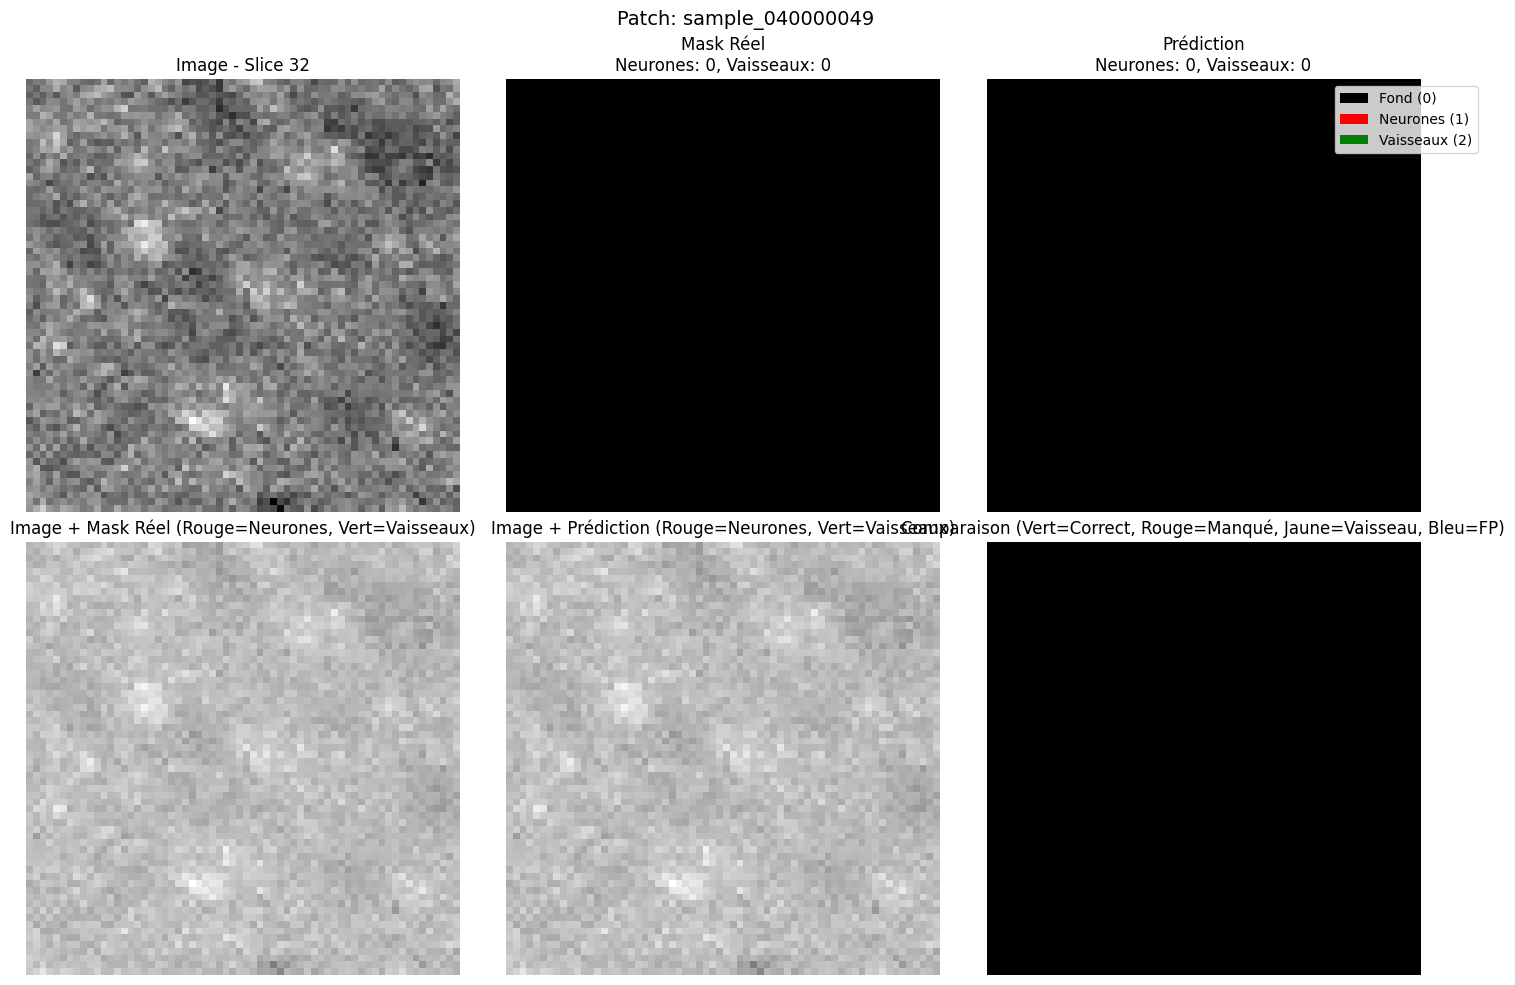


Statistiques du patch sample_040000049:
  Neurones réels: 717
  Vaisseaux réels: 0
  Neurones prédits: 709
  Vaisseaux prédits: 0

--- Patch 7/10: sample_032000293 ---


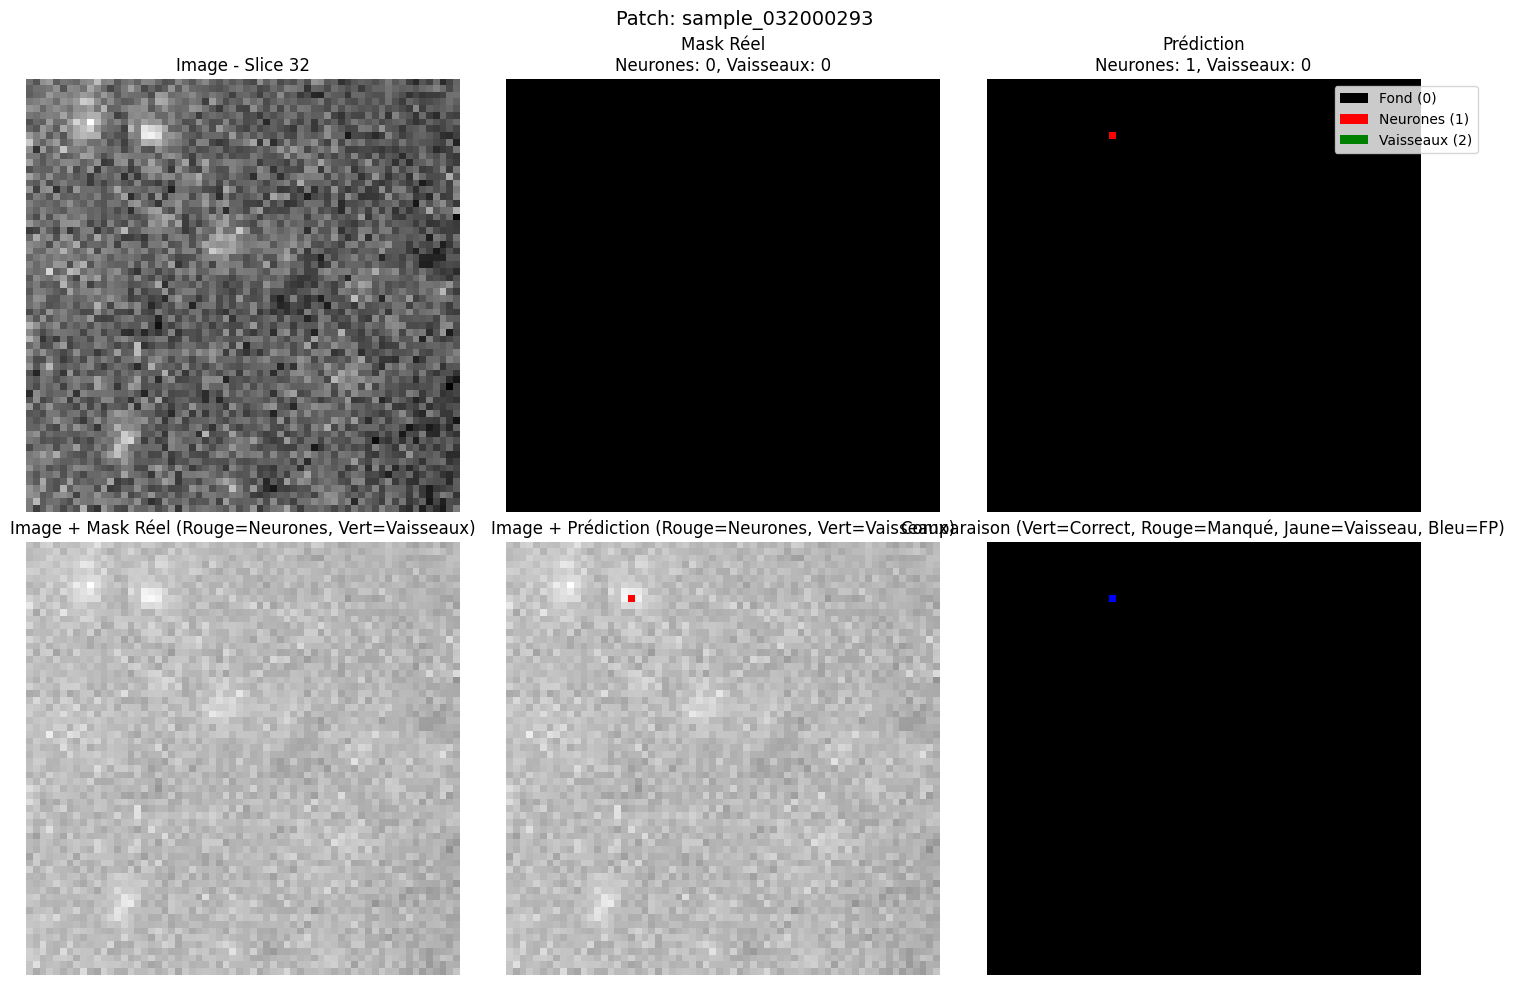


Statistiques du patch sample_032000293:
  Neurones réels: 377
  Vaisseaux réels: 0
  Neurones prédits: 313
  Vaisseaux prédits: 0

--- Patch 8/10: sample_081000383 ---


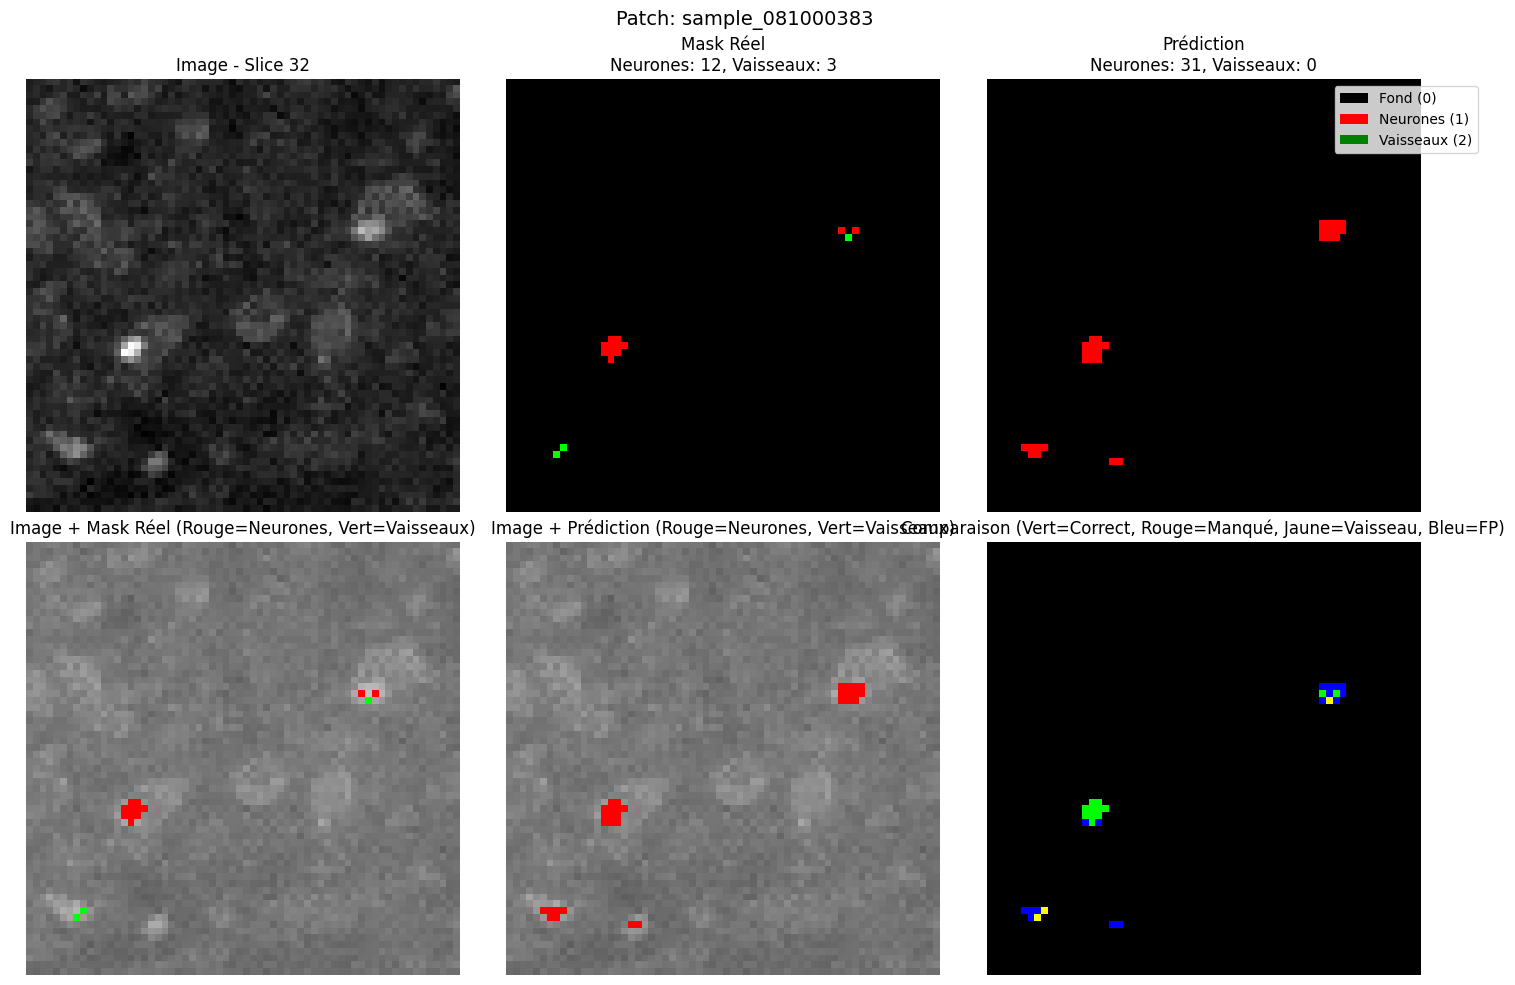


Statistiques du patch sample_081000383:
  Neurones réels: 357
  Vaisseaux réels: 27
  Neurones prédits: 834
  Vaisseaux prédits: 0

--- Patch 9/10: sample_034000040 ---


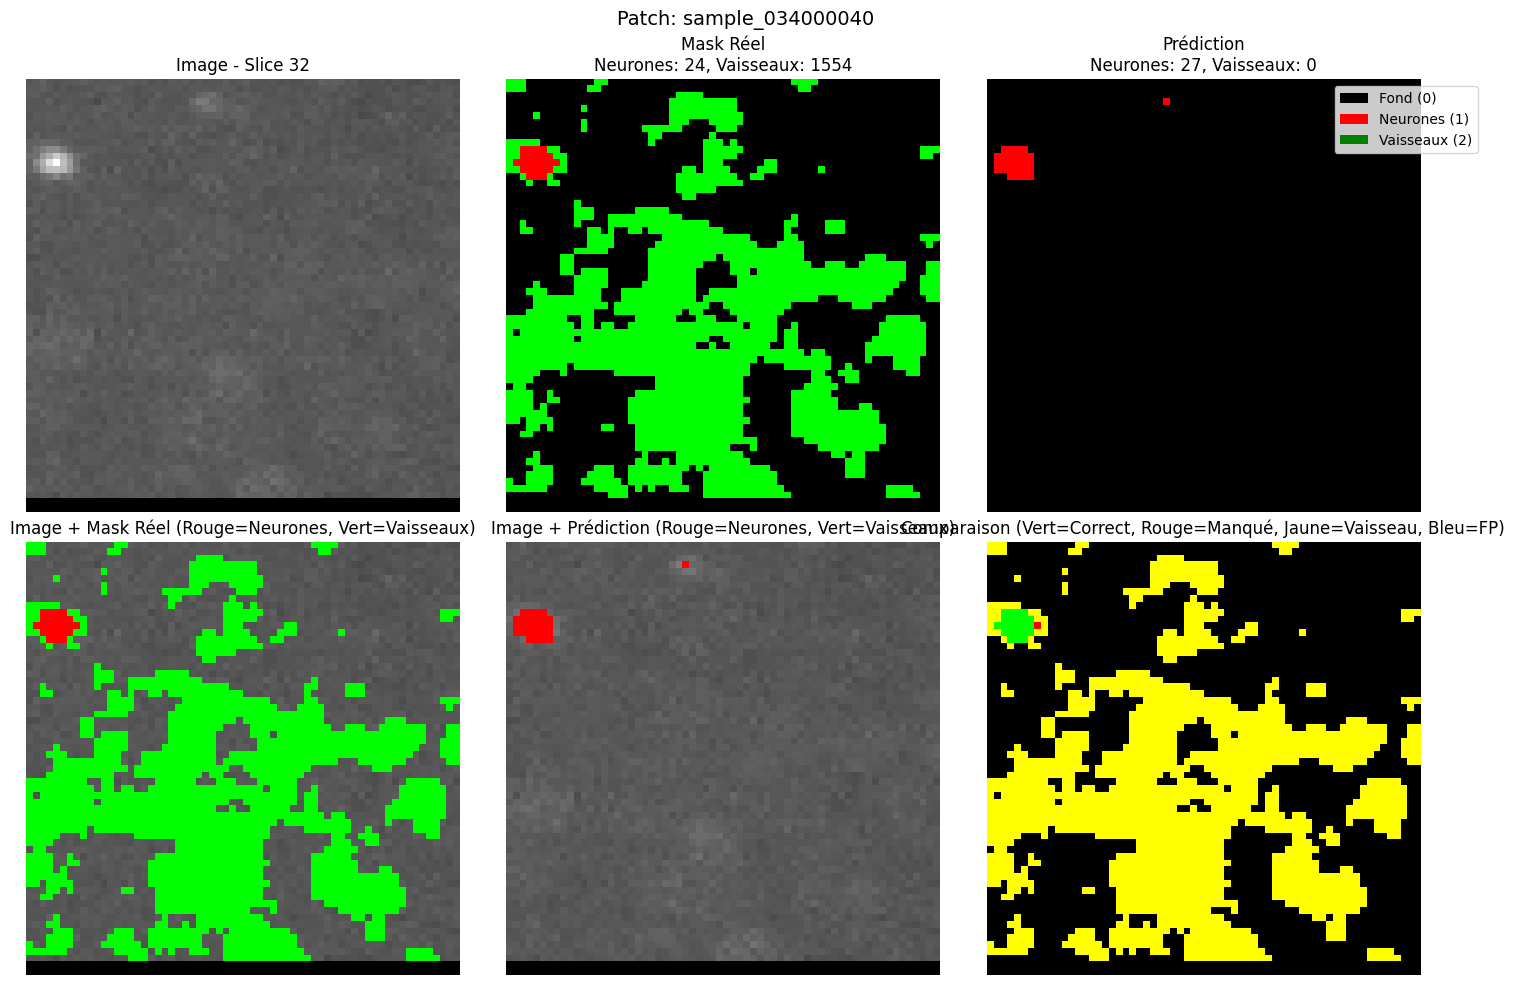


Statistiques du patch sample_034000040:
  Neurones réels: 698
  Vaisseaux réels: 100,804
  Neurones prédits: 942
  Vaisseaux prédits: 43

--- Patch 10/10: sample_038000250 ---


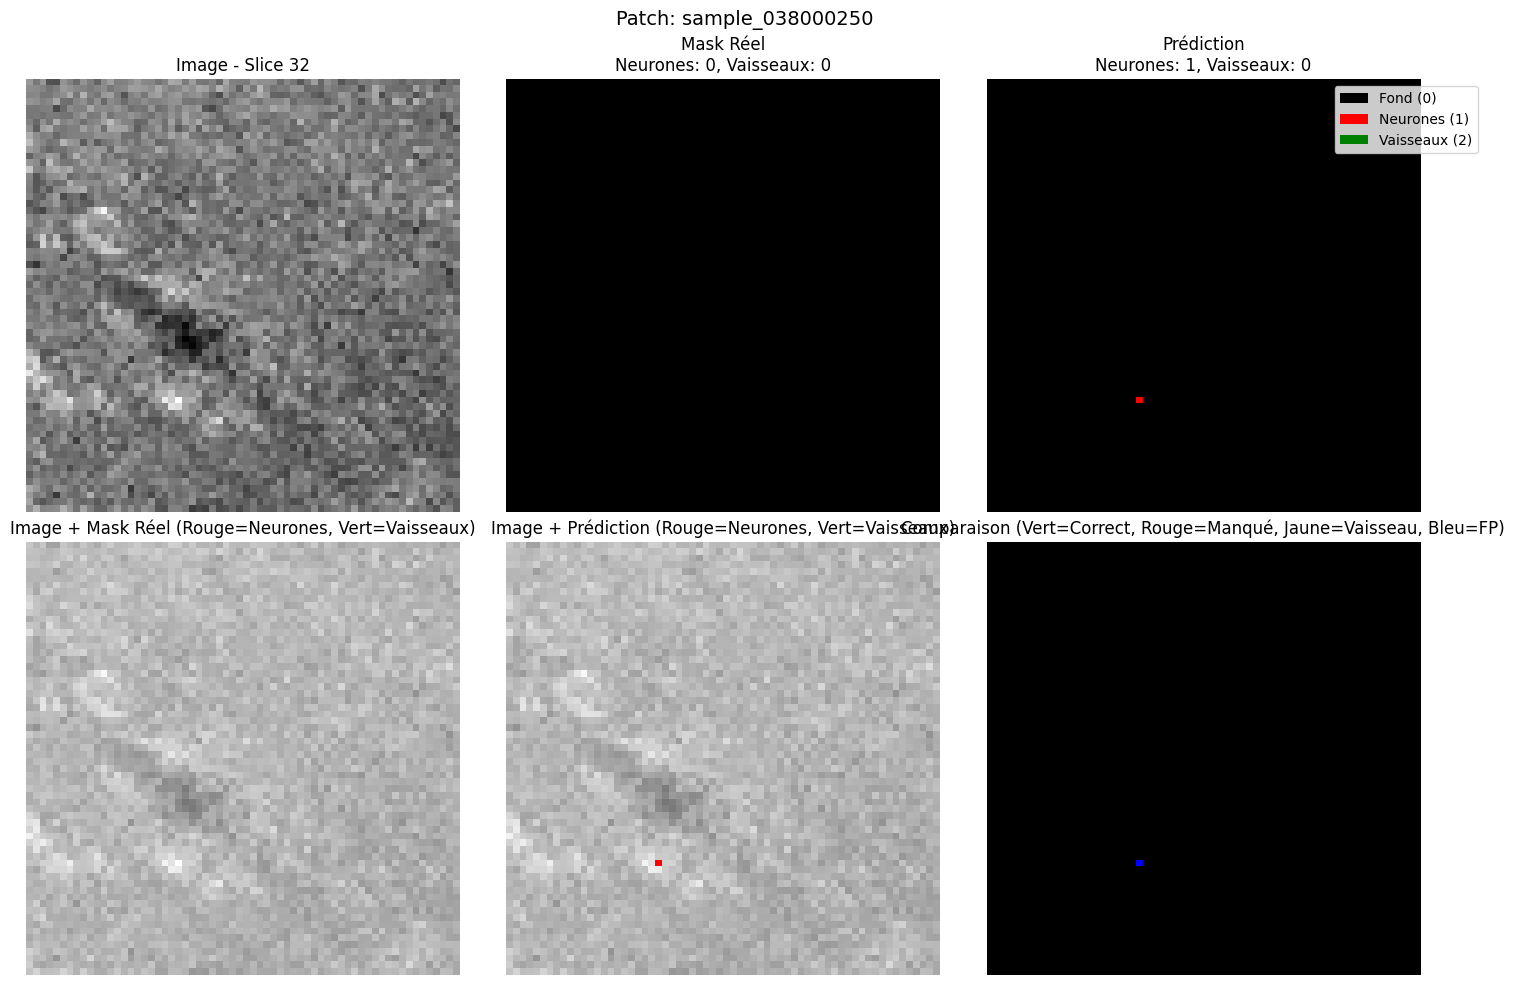


Statistiques du patch sample_038000250:
  Neurones réels: 133
  Vaisseaux réels: 0
  Neurones prédits: 275
  Vaisseaux prédits: 0


In [14]:
print("\n" + "=" * 50)
print("VISUALISATION DES PRÉDICTIONS")
print("=" * 50)

for i, pred_data in enumerate(predictions):
    print(f"\n--- Patch {i+1}/{len(predictions)}: {pred_data['name']} ---")
    visualize_prediction_3class(
        pred_data["image"],
        pred_data["mask_real"],
        pred_data["pred"],
        pred_data["name"]
    )


In [17]:
print("\n" + "=" * 50)
print("STATISTIQUES GLOBALES")
print("=" * 50)

total_neurons_real = 0
total_neurons_pred = 0
total_vessels_real = 0
total_vessels_pred = 0

for pred_data in predictions:
    mask_real = pred_data["mask_real"]
    pred = pred_data["pred"]
    
    total_neurons_real += (mask_real == 1).sum()
    total_vessels_real += (mask_real == 2).sum()
    total_neurons_pred += (pred == 1).sum()
    total_vessels_pred += (pred == 2).sum()

print(f"Total neurones réels: {total_neurons_real:,}")
print(f"Total neurones prédits: {total_neurons_pred:,}")
print(f"Ratio neurones prédits/réels: {total_neurons_pred/total_neurons_real if total_neurons_real > 0 else 0:.2f}")
print()
print(f"Total vaisseaux réels: {total_vessels_real:,}")
print(f"Total vaisseaux prédits: {total_vessels_pred:,}")
print(f"Ratio vaisseaux prédits/réels: {total_vessels_pred/total_vessels_real if total_vessels_real > 0 else 0:.2f}")

print("\n" + "=" * 50)

print(f"Prédictions sauvegardées dans: {output_pred_dir}")
print(f"  - Format: .npy (fichiers numpy)")
print(f"  - Noms: patch_*_pred.npy")


STATISTIQUES GLOBALES
Total neurones réels: 6,037
Total neurones prédits: 7,816
Ratio neurones prédits/réels: 1.29

Total vaisseaux réels: 100,831
Total vaisseaux prédits: 52
Ratio vaisseaux prédits/réels: 0.00

Prédictions sauvegardées dans: /mnt/x/segmentation_cfos/outputs/swin_3class_slices40_focal/predictions
  - Format: .npy (fichiers numpy)
  - Noms: patch_*_pred.npy
